# Static Variable in Python

## Definition

A **static variable** is a variable that belongs to the **class itself**, rather than to a particular object.

In Python, it is commonly called a **class variable**.

It is defined **inside the class but outside the methods**.

```python
class Student:

    school = "ABC School"       # static/class variable

    def __init__(self, name):
        self.name = name        # instance variable

student1 = Student("Prasad")
student2 = Student("Rahul")

print(student1.school)
print(student2.school)
```
### Output
```text
ABC School
ABC School
```
### Conceptually

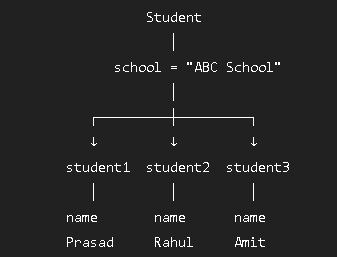
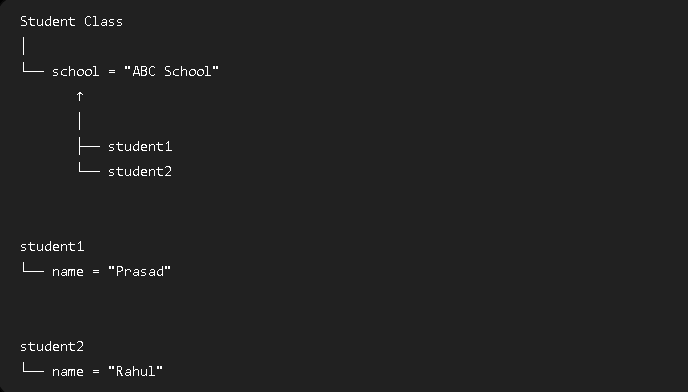

In [2]:
class Student:
    
    school = "ABC School"           # static/class variable
    
    def __init__(self, name):
        self.name = name

student1 = Student("Nitish")
student2 = Student("Ankita")

print(student1.school)
print(student2.school)


ABC School
ABC School


# Accessing a Class Variable

We can access a class variable using the class name:
```python
print(Student.school)
```
### Output:

ABC School

We can also access it through an object:
```python
print(student1.school)
```
### Output:

ABC School

However, the variable itself belongs to the `class`, not to `student1.`

In [3]:
class Student:
    
    school = "ABC School"           # static/class variable
    
    def __init__(self, name):
        self.name = name

print(Student.school)

ABC School


# Why Use a Static/Class Variable?

**We use a class variable when a value is common/shared among all objects.**

# Private Static Variable in Python

A **private static variable** in Python means a **private class variable** that is shared by all objects of the class.

* **Static/Class variable** → shared by all objects
* **Private** → starts with `__` (double underscore)
* It is defined **inside the class but outside methods**

## ATM Example

Suppose we want to keep track of the **total number of ATM objects created**, but we don't want it to be directly accessed normally from outside the class.

```python
class Atm:

    __counter = 0       # Private static/class variable

    def __init__(self):
        Atm.__counter += 1

        self.pin = ""
        self.balance = 0


a1 = Atm()
a2 = Atm()
a3 = Atm()

print(Atm.__counter)
```

This gives:

```text
AttributeError
```

because `__counter` is a **private class variable**.

---

## How can we access it?

We can create a method inside the class:

```python
class Atm:

    __counter = 0       # Private static/class variable

    def __init__(self):
        Atm.__counter += 1

        self.pin = ""
        self.balance = 0

    def get_counter(self):
        return Atm.__counter


a1 = Atm()
a2 = Atm()
a3 = Atm()

print(a1.get_counter())
```

Output:

```text
3
```

### What happened?

When we create the objects:

```python
a1 = Atm()
a2 = Atm()
a3 = Atm()
```

The constructor runs three times.

```python
Atm.__counter += 1
```

So:

```text
First object  → counter = 1
Second object → counter = 2
Third object  → counter = 3
```

The important point is that **there is only one `__counter` shared by the entire class**.

---

# Why is it called "private static"?

### `__counter`

The `__` means **private/name-mangled**.

### `counter` belongs to the class

It is not created using `self`:

```python
self.counter
```

Instead, it belongs to the class:

```python
Atm.__counter
```

Therefore:

```text
__counter
   ↓
Private
   +
Class variable
   ↓
Private static variable
```

---

# Compare with Instance Variable

```python
class Atm:

    __counter = 0       # Private static variable

    def __init__(self):
        Atm.__counter += 1

        self.pin = ""       # Instance variable
        self.balance = 0    # Instance variable
```

Here:

| Variable       | Type                          | Belongs to        |
| -------------- | ----------------------------- | ----------------- |
| `__counter`    | Private static/class variable | Class             |
| `self.pin`     | Instance variable             | Individual object |
| `self.balance` | Instance variable             | Individual object |

For example:

```text
Atm
│
└── __counter = 3        ← One shared variable
     
a1
├── pin
└── balance

a2
├── pin
└── balance

a3
├── pin
└── balance
```

So **each ATM object has its own `pin` and `balance`, but all ATM objects share the same `__counter`.**

---

# Complete Example

```python
class Atm:

    __counter = 0

    def __init__(self):
        Atm.__counter += 1

        self.pin = ""
        self.balance = 0

    def get_counter(self):
        return Atm.__counter


a1 = Atm()
a2 = Atm()
a3 = Atm()

print(a1.get_counter())
print(a2.get_counter())
print(a3.get_counter())
```

Output:

```text
3
3
3
```

All three objects see the **same counter** because `__counter` is a class variable.

---

## Important: Why use `Atm.__counter` instead of `self.__counter`?

We want to modify the **class variable**:

```python
Atm.__counter += 1
```

This clearly means:

> "Increase the counter belonging to the `Atm` class."

If you're working with a class variable, using the **class name** is generally clearer:

```python
ClassName.variable
```

rather than:

```python
self.variable
```

---

## Memory Trick 🧠

```text
self.variable
     ↓
Instance variable
     ↓
Each object gets its own copy


ClassName.variable
     ↓
Class/static variable
     ↓
Shared by all objects


__variable
     ↓
Private/name-mangled
```

Therefore:

```python
Atm.__counter
```

means:

> **Private class/static variable of the Atm class**


In [ ]:
class Atm():
    
    __counter = 0
    
    def __init__(self):
        
        Atm.__counter = Atm.__counter + 1
        
        self.pin = ""
        self.balance = 0
        
    def get_counter(self):
        return Atm.__counter 
    
    @classmethod
    def get_counter(cls):
        return cls.__counter

sbi = Atm()
hdfc = Atm()
icici = Atm()

print(sbi.get_counter())
print(hdfc.get_counter())
print(icici.get_counter())

print(Atm._Atm__counter)       # Dont access it like this instead make a class method and access it

print(Atm.get_counter())       # calling using class method


    
    

3
3
3
3
3


# Why don't we pass `cls` when calling a `@classmethod`?

You may notice:

```python
@classmethod
def get_counter(cls):
    return cls.__counter
```

The method has a parameter:

```python
cls
```

But when we call it:

```python
print(Atm.get_counter())
```

we **don't pass any argument**.

Why?

Because Python **automatically passes the class itself** as the first argument to a class method.

---

## 1. What happens with a normal method?

Consider an instance method:

```python
class Atm:

    def get_balance(self):
        return self.balance
```

When we call:

```python
sbi.get_balance()
```

we don't write:

```python
sbi.get_balance(sbi)
```

Python automatically passes `sbi` as `self`.

Conceptually:

```python
Atm.get_balance(sbi)
```

So:

```text
sbi.get_balance()
       ↓
Python automatically passes sbi
       ↓
self = sbi
```

---

# 2. The same thing happens with `@classmethod`

For a class method:

```python
@classmethod
def get_counter(cls):
    return cls.__counter
```

when we call:

```python
Atm.get_counter()
```

Python automatically passes the **class `Atm`** as `cls`.

Conceptually, Python does:

```python
Atm.get_counter(Atm)
```

Therefore:

```text
Atm.get_counter()
       ↓
Python automatically passes Atm
       ↓
cls = Atm
```

---
# 3. Compare `self` and `cls`

This is very important:

| Method type     | First parameter        | Python automatically passes |
| --------------- | ---------------------- | --------------------------- |
| Instance method | `self`                 | Object                      |
| Class method    | `cls`                  | Class                       |
| Static method   | No automatic parameter | Nothing                     |

